In [1]:
%pip install scikit-image

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import tifffile
from skimage import filters, measure
from skimage.io import imread

In [3]:
filename = 'Img01_mRNA.tif'
img01_cells = imread(filename)

In [4]:
print(type(img01_cells))
print(img01_cells.shape)

<class 'numpy.ndarray'>
(366, 594)


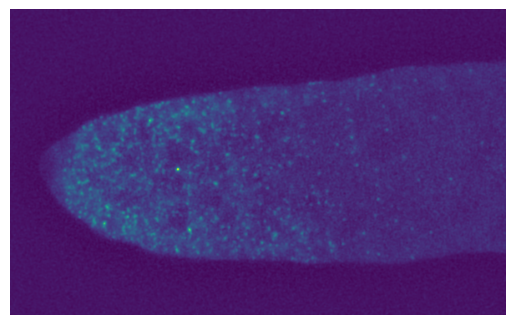

In [5]:
plt.imshow(img01_cells)
plt.axis('off')
plt.show()

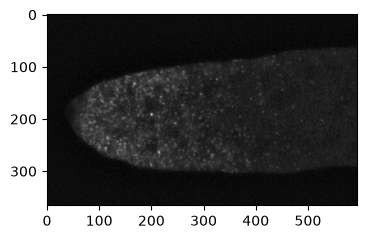

In [6]:
fh, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.imshow(img01_cells, cmap='gray')

In [7]:
img01_cells.shape

(366, 594)

In [8]:
img01_cells.flatten().shape

(217404,)

Text(0, 0.5, 'Count')

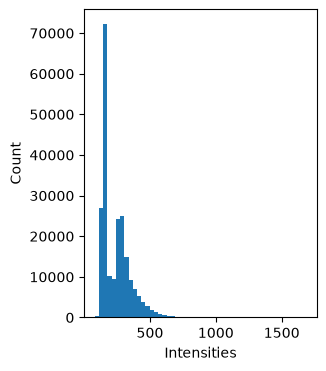

In [9]:
fh, ax = plt.subplots(1, 1, figsize=(3, 4))
ax.hist(img01_cells.flatten(), bins=50)
ax.set_xlabel('Intensities')
ax.set_ylabel('Count')

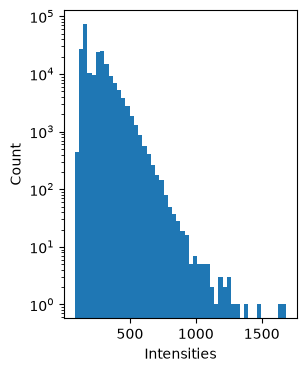

In [10]:
fh, ax = plt.subplots(1, 1, figsize=(3, 4))
ax.hist(img01_cells.flatten(), bins=50)
ax.set_xlabel('Intensities')
ax.set_ylabel('Count')
ax.set_yscale('log')

skimage.filters.thresholding.threshold_isodata
skimage.filters.thresholding.threshold_li
skimage.filters.thresholding.threshold_mean
skimage.filters.thresholding.threshold_minimum
skimage.filters.thresholding.threshold_otsu
skimage.filters.thresholding.threshold_triangle
skimage.filters.thresholding.threshold_yen
(<Figure size 800x500 with 8 Axes>, array([<Axes: title={'center': 'Original'}>,
       <Axes: title={'center': 'Isodata'}>,
       <Axes: title={'center': 'Li'}>, <Axes: title={'center': 'Mean'}>,
       <Axes: title={'center': 'Minimum'}>,
       <Axes: title={'center': 'Otsu'}>,
       <Axes: title={'center': 'Triangle'}>,
       <Axes: title={'center': 'Yen'}>], dtype=object))


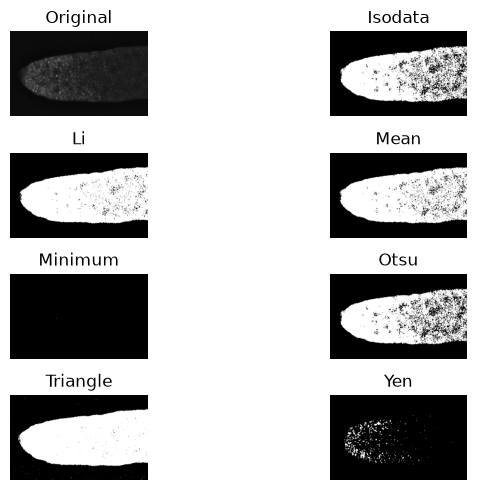

In [11]:
testing = filters.try_all_threshold(img01_cells)
print(testing)

In [12]:
thresh = filters.threshold_yen(img01_cells)
print(thresh)

513


In [13]:
img01_cells.shape

(366, 594)

In [14]:
mask = img01_cells > thresh
print(mask.shape)
print(np.unique(mask))

(366, 594)
[False  True]


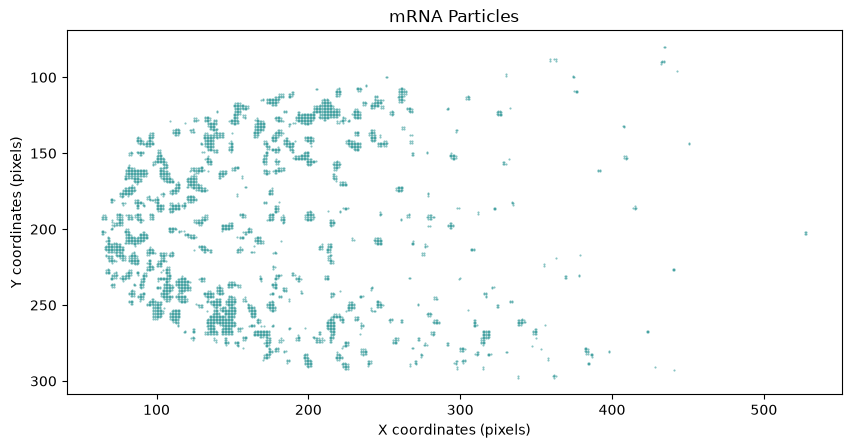

In [15]:
x, y = np.where(img01_cells >= thresh)
fh, ax = plt.subplots(1, 1, figsize=(10, 6))
plt.scatter(y, x, s=1, alpha=0.5, c='teal', marker='.')
plt.gca().set_aspect('equal', adjustable='box')
plt.title("mRNA Particles")
plt.xlabel("X coordinates (pixels)")
plt.ylabel("Y coordinates (pixels)")
plt.gca().invert_yaxis()
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/mrna_particles_scatter.png")
plt.show()

In [16]:
print(type(img01_cells))
print(img01_cells.shape)

<class 'numpy.ndarray'>
(366, 594)


In [17]:
import pandas as pd
from skimage.feature import blob_log
from skimage import img_as_float

In [18]:
img = imread(filename)
print(f"Image Data Type: {img.dtype}")
print(f"Image Max Raw Intensity: {img.max()}")

Image Data Type: uint16
Image Max Raw Intensity: 1685


In [19]:
img_float = img_as_float(img01_cells)
spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=0.001)
print(f"Total Unique Particles Isolated: {len(spots)}")

Total Unique Particles Isolated: 447


In [20]:
print(sns.get_dataset_names())

['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 'taxis', 'tips', 'titanic']


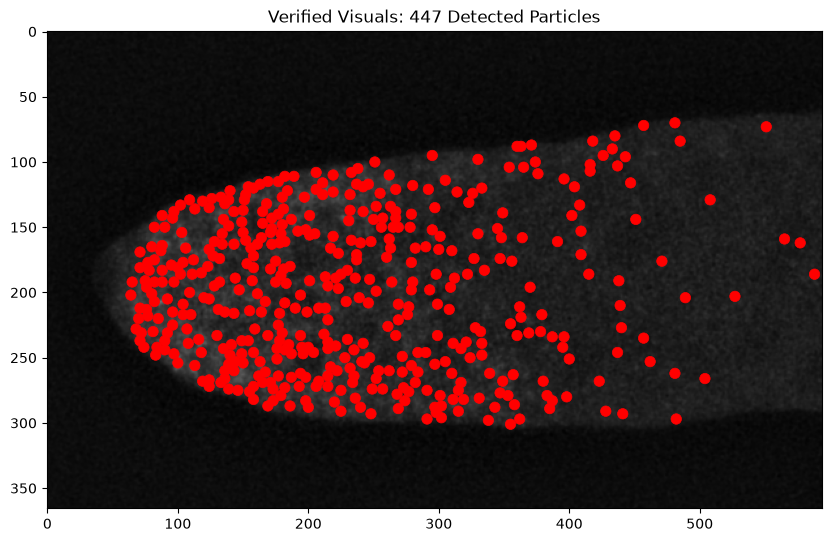

In [21]:
img_2d = img01_cells
img_display = img_2d.astype(float)
fig, ax = plt.subplots(figsize=(10, 10))
plt.imshow(img_display, cmap='gray', vmin=img_display.min(), vmax=img_display.max())
for spot in spots:
    y, x, r = spot
    circle = plt.Circle((x, y), radius=4, color='red', fill=True, linewidth=0.5)
    ax.add_patch(circle)
ax.set_title(f"Verified Visuals: {len(spots)} Detected Particles")
ax.axis('on')
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/verified_mrna_visual.png", dpi=300)
plt.show()

In [22]:
spots_df = pd.DataFrame(spots, columns=["y", "x", "sigma"])
print(spots_df.head())

       y      x     sigma
0  191.0  201.0  1.444444
1  264.0  215.0  1.888889
2  256.0  113.0  1.666667
3  132.0  168.0  2.111111
4  248.0  140.0  1.444444


In [23]:
print(spots.shape)
print(spots[:5])

(447, 3)
[[191.         201.           1.44444444]
 [264.         215.           1.88888889]
 [256.         113.           1.66666667]
 [132.         168.           2.11111111]
 [248.         140.           1.44444444]]


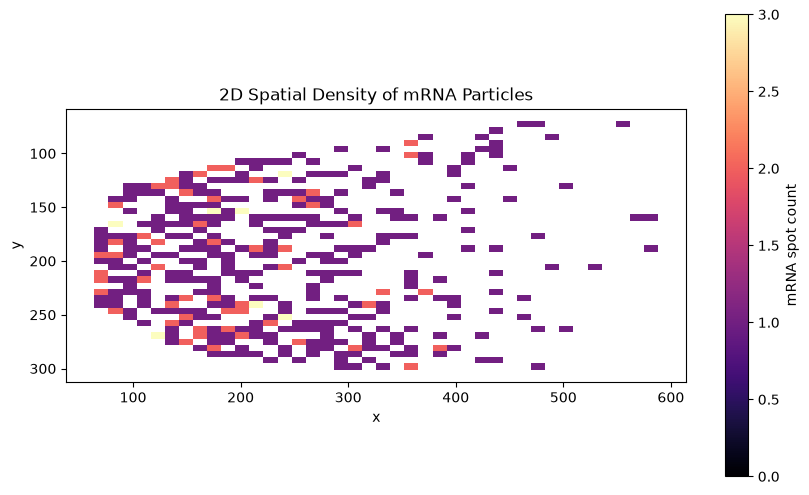

In [24]:
x, y = np.where(img01_cells >= thresh)
fh, ax = plt.subplots(figsize=(10, 6))
sns.histplot(data=spots_df, x="x", y="y", bins=40, cmap="magma", cbar=True, cbar_kws={"label": "mRNA spot count"}, ax=ax)
ax.invert_yaxis()
ax.set_aspect("equal")
plt.title("2D Spatial Density of mRNA Particles")
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/mrna_heatmap.png")
plt.show()

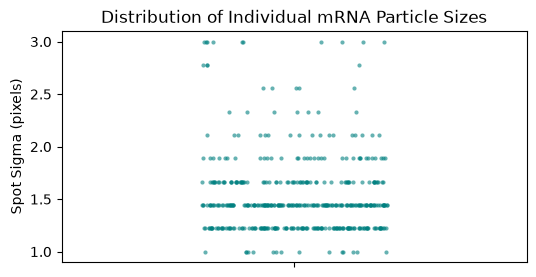

In [25]:
fh, ax = plt.subplots(1, 1, figsize=(6, 3))
sns.stripplot(data=spots_df, y="sigma", color="teal", size=3, alpha=0.6, jitter=0.2, ax=ax)
plt.title("Distribution of Individual mRNA Particle Sizes")
plt.ylabel("Spot Sigma (pixels)")
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/mrna_size_distr.png")
plt.show()
# Tight, dark band of the overlapping dots tells us that the found mRNA particles are the same physical size
# sign that the detectin of the single-molecule mRNAs are true

# The dots above the bands (outliers) are the abnormally large spots that are often either active transcription sites
# or overlapping transcripts

# The darkest areas (where many dots overlap)= mode (most common value)

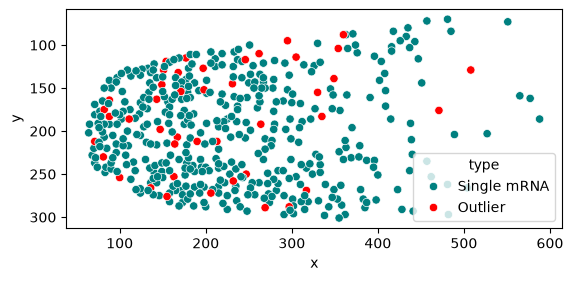

In [26]:
spots_df["type"] = np.where(spots_df["sigma"] > 2.0, "Outlier", "Single mRNA")
sns.scatterplot(data=spots_df, x="x", y="y", hue="type", palette={"Single mRNA": "teal", "Outlier": "red"})
plt.gca().invert_yaxis()
plt.gca().set_aspect("equal")
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/true_vs_outlier_mrna.png")
plt.show()

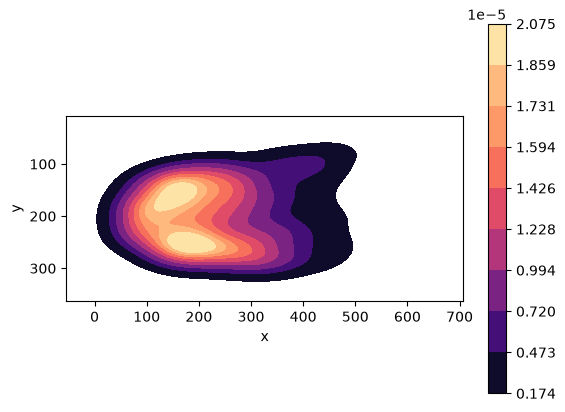

In [27]:
sns.kdeplot(data=spots_df, x="x", y="y", fill=True, cmap="magma", cbar=True)
plt.gca().invert_yaxis()
plt.gca().set_aspect("equal")
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/mrna_kde.png")
plt.show()
# Brightest/Hottest color (yellow)= mRNA hotspots where they're packed close together
# Medium colors (purple/red)= steady spread of individual cytoplasmic mRNA
# Darkest= very few or zero mRNA particles

In [28]:
counts_table = spots_df["type"].value_counts().reset_index()
counts_table.columns = ["Spot Type", "Count"]
print(counts_table)
counts_table

     Spot Type  Count
0  Single mRNA    404
1      Outlier     43


,Spot Type,Count
0,Single mRNA,404
1,Outlier,43


In [29]:
summary_table = spots_df.groupby("type", as_index=False).agg(Total_Spots=("sigma", "count"), Mean_Sigma=("sigma", "mean"), Min_Sigma=("sigma", "min"), Max_Sigma=("sigma", "max"))
summary_table = summary_table.round(2)
print(summary_table)

          type  Total_Spots  Mean_Sigma  Min_Sigma  Max_Sigma
0      Outlier           43        2.47       2.11       3.00
1  Single mRNA          404        1.43       1.00       1.89


In [30]:
print(spots_df.head(10))

       y      x     sigma         type
0  191.0  201.0  1.444444  Single mRNA
1  264.0  215.0  1.888889  Single mRNA
2  256.0  113.0  1.666667  Single mRNA
3  132.0  168.0  2.111111      Outlier
4  248.0  140.0  1.444444  Single mRNA
5  236.0  116.0  1.888889  Single mRNA
6  208.0  246.0  1.666667  Single mRNA
7  288.0  200.0  1.888889  Single mRNA
8  124.0  326.0  1.666667  Single mRNA
9  141.0  201.0  1.666667  Single mRNA


In [31]:
spots_df.to_csv(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/mrna_spots_full.csv", index=False)
summary_table.to_csv(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/mrna_summary.csv", index=False)

In [85]:
import glob
batch_mrna_dir = 'Batch'
filepaths = glob.glob(os.path.join(batch_mrna_dir, '*.tif'))
print(len(filepaths))

2


In [117]:
from skimage import feature, filters, util

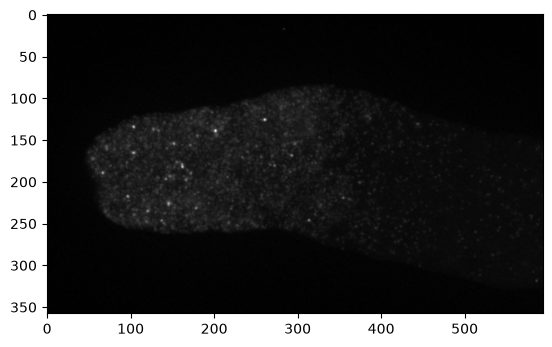

<class 'numpy.ndarray'>
['Batch/Img04_mRNA.tif', 'Batch/Img02_mRNA.tif']


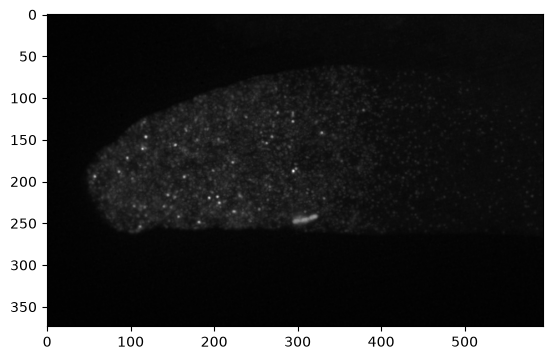

<class 'numpy.ndarray'>
['Batch/Img04_mRNA.tif', 'Batch/Img02_mRNA.tif']
                  Image  Single_mRNA
0  Batch/Img04_mRNA.tif         1629
1  Batch/Img02_mRNA.tif         1930


In [87]:
counts = []
for file in filepaths:
    img = tifffile.imread(file)
    plt.imshow(img, cmap="gray")
    plt.show()
    print(type(img))
    print(filepaths)

    img_norm = (img - img.min()) / (img.max() - img.min())

    spots = feature.blob_log(img_norm, min_sigma=1, max_sigma=4, num_sigma=10, threshold=0.01, overlap=0.1)
    if len(spots) > 0:
        single_count = int((spots[:, 2] <= 2.0).sum())
    else:
        single_count = 0

    counts.append({"Image": str(file), "Single_mRNA": single_count})

counts_table = pd.DataFrame(counts)
print(counts_table)

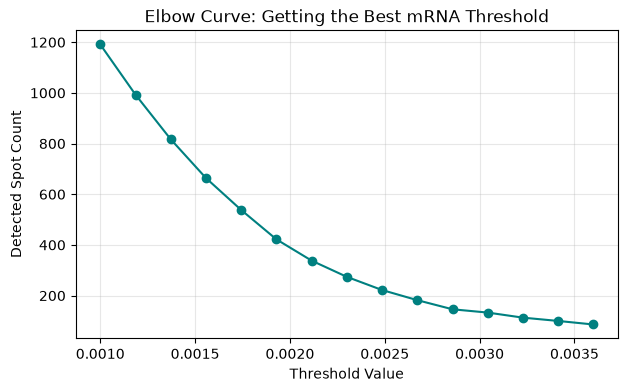

In [88]:
img = tifffile.imread(filepaths[0])
img_float = img_as_float(img)

thresholds = np.linspace(0.001, 0.0036, 15)
spot_counts = []
for t in thresholds:
    spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=t, overlap=0.0)
    spot_counts.append(len(spots))

plt.figure(figsize=(7, 4))
plt.plot(thresholds, spot_counts, marker="o", color="teal")
plt.xlabel("Threshold Value")
plt.ylabel("Detected Spot Count")
plt.title("Elbow Curve: Getting the Best mRNA Threshold")
plt.grid(True, alpha=0.3)
plt.show()

In [89]:
drops = -np.diff(spot_counts)
elbow_index = np.argmax(np.diff(drops)) + 1
best_thresh = thresholds[elbow_index]
print(f"Suggested Elbow Threshold: {best_thresh:.4f}")
print(f"Spots detected at this threshold: {spot_counts[elbow_index]}")

Suggested Elbow Threshold: 0.0030
Spots detected at this threshold: 133


In [90]:
counts = []
for file in filepaths:
    img = tifffile.imread(file)
    img_float = img_as_float(img)
    spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)
# Lessen threshold because 0.0030 was too strict
    counts.append({"Image": os.path.basename(file), "Total_Unique_Particles": len(spots)})

    counts_table = pd.DataFrame(counts)
    print(counts_table)

            Image  Total_Unique_Particles
0  Img04_mRNA.tif                     396
            Image  Total_Unique_Particles
0  Img04_mRNA.tif                     396
1  Img02_mRNA.tif                     404


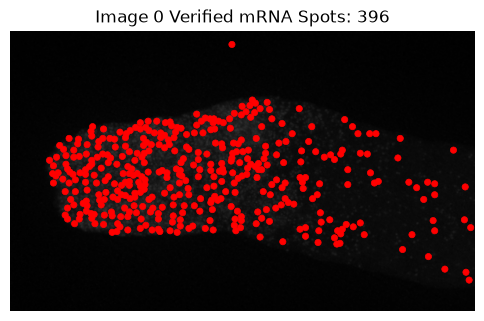

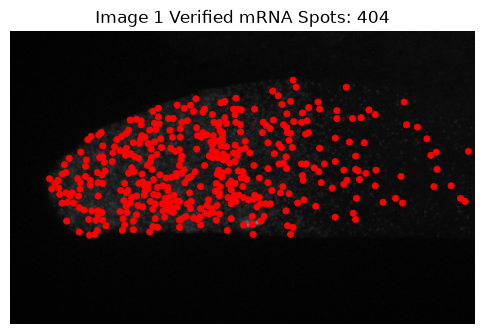

In [91]:
for i, file in enumerate (filepaths):
    img = tifffile.imread(file)
    img_float = img_as_float(img)
    spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    fh, ax = plt.subplots(figsize=(6, 6))
    plt.imshow(img, cmap="gray")
    for spot in spots:
        y, x, r = spot
        circle = plt.Circle((x, y), radius=4, color="red", linewidth=0.5, fill=True)
        ax.add_patch(circle)

    ax.set_title(f"Image {i} Verified mRNA Spots: {len(spots)}")
    ax.axis("off")
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/verified_mrna_{i}.png")
    plt.close(fig)

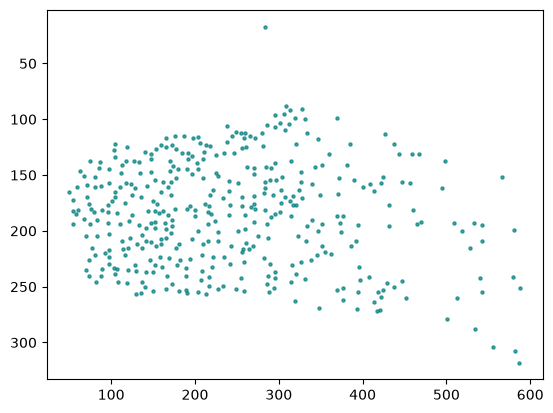

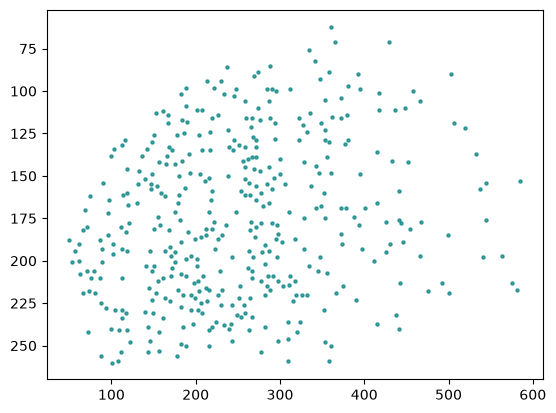

In [92]:
for i, file in enumerate (filepaths):
    img = tifffile.imread(file)
    img_float = img_as_float(img)
    spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    y = spots[:, 1]
    x = spots[:, 0]
    plt.scatter(y, x, s=20, alpha=0.7, c="teal", marker=".")
    plt.gca().invert_yaxis()
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/figure_{i}.png")
    plt.show()
    plt.close()

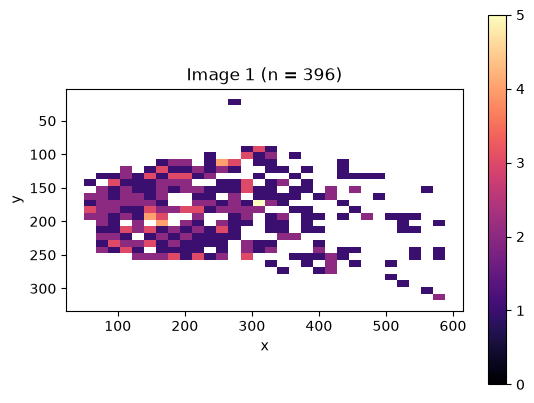

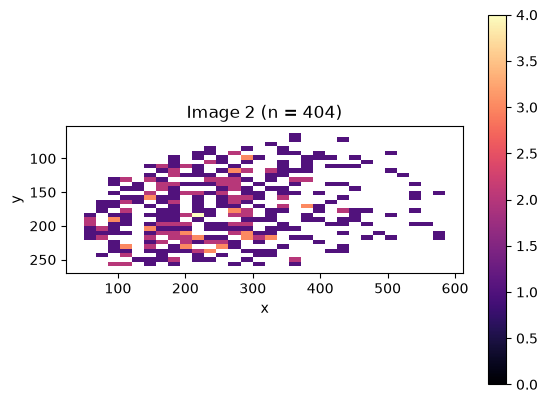

In [93]:
all_spots = []
for i, file in enumerate(filepaths[:2]):
    img = tifffile.imread(file)
    img_float = img_as_float(img)
    spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    df = pd.DataFrame(spots, columns=["y", "x", "sigma"])
    df["Image"] = f"Image {i + 1}"
    all_spots.append(df)

    sns.histplot(data=df, x="x", y="y", bins=30, cmap="magma", cbar=True)
    plt.gca().invert_yaxis()
    plt.gca().set_aspect("equal")
    plt.title(f"Image {i +1} (n = {len(df)})")
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/histplot_{i}.png")
    plt.show()
    plt.close()

In [94]:
spots_df = pd.concat(all_spots, ignore_index=True)
print(spots_df.head())
print(spots_df["Image"].value_counts())
print(spots_df.tail())

       y      x     sigma    Image
0  139.0  202.0  1.222222  Image 1
1  125.0  261.0  1.222222  Image 1
2  134.0  104.0  1.222222  Image 1
3  182.0  162.0  1.222222  Image 1
4  165.0  104.0  1.222222  Image 1
Image
Image 2    404
Image 1    396
Name: count, dtype: int64
         y      x     sigma    Image
795  167.0  120.0  1.000000  Image 2
796   89.0  358.0  1.000000  Image 2
797  119.0  167.0  1.222222  Image 2
798  125.0  186.0  1.222222  Image 2
799  239.0  282.0  2.333333  Image 2


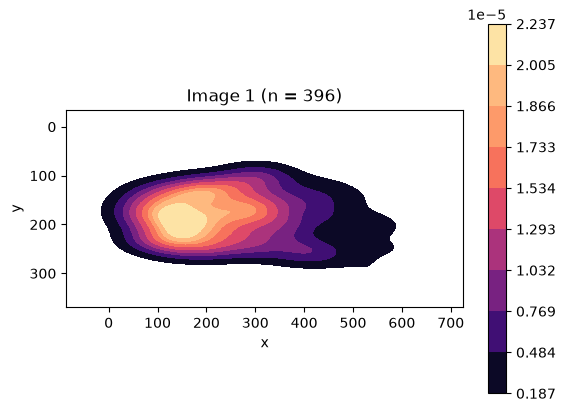

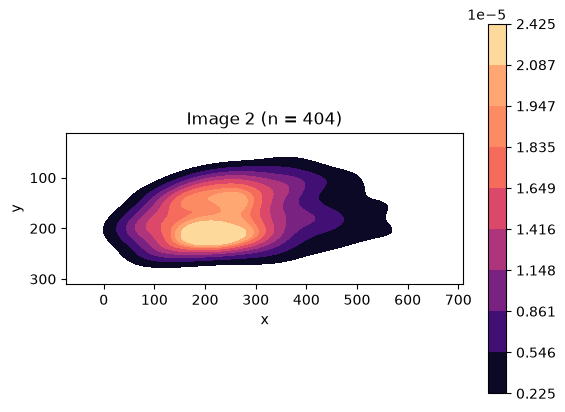

In [95]:
all_spots = []
for i, file in enumerate(filepaths[:2]):
    img = tifffile.imread(file)
    img_float = img_as_float(img)
    spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    df = pd.DataFrame(spots, columns=["y", "x", "sigma"])
    df["Image"] = f"Image {i + 1}"
    all_spots.append(df)

    sns.kdeplot(data=df, x="x", y="y", fill=True, cmap="magma", cbar=True)
    plt.gca().invert_yaxis()
    plt.gca().set_aspect("equal")
    plt.title(f"Image {i +1} (n = {len(df)})")
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/kde_heatmap_{i}.png")
    plt.show()
    plt.close()

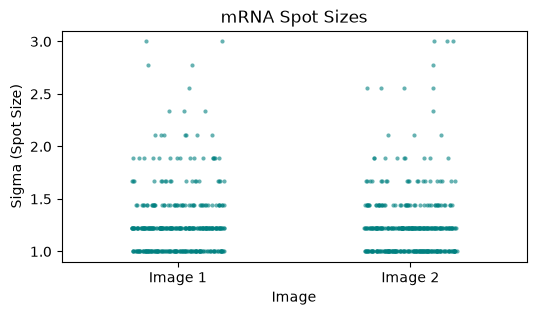

In [96]:
fh, ax = plt.subplots(1, 1, figsize=(6, 3))
sns.stripplot(data=spots_df, x="Image", y="sigma", color="teal", size=3, jitter=0.2, alpha=0.6, ax=ax)
plt.ylabel("Sigma (Spot Size)")
plt.title("mRNA Spot Sizes")
plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/stripplot.png")
plt.show()

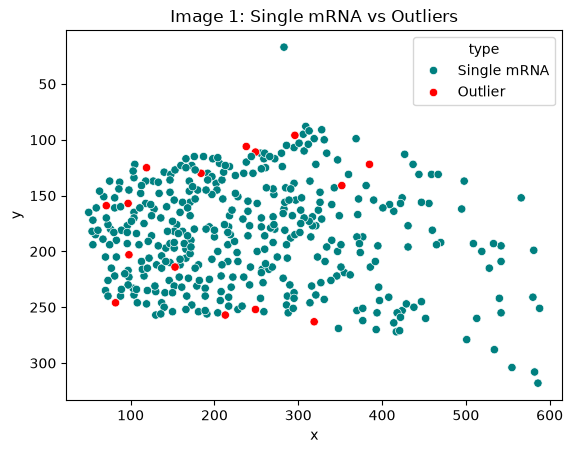

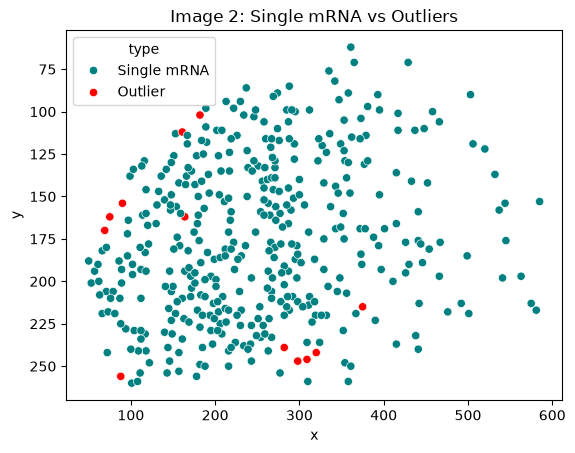

In [97]:
spots_df["type"] = np.where(spots_df["sigma"] > 2.0, "Outlier", "Single mRNA")
for i, img_name in enumerate(spots_df["Image"].unique()):
    sub_df = spots_df[spots_df["Image"] == img_name]
    sns.scatterplot(data=sub_df, x="x", y="y", hue="type", palette={"Single mRNA": "teal", "Outlier": "red"})
    plt.gca().invert_yaxis()
    plt.title(f"{img_name}: Single mRNA vs Outliers")
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/mrna_vs_outlier_scatter_{i}.png")
    plt.show()
    plt.close()

In [98]:
spots_df["type"] = np.where(spots_df["sigma"] > 2.0, "Outlier", "Single mRNA")
for i, img_name in enumerate(spots_df["Image"].unique()):
    sub_df = spots_df[spots_df["Image"] == img_name]
    counts_table = sub_df["type"].value_counts().reset_index()
    counts_table.columns = ["Type", "Count"]
    counts_table.to_csv(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/mrna_vs_outlier_scatter_{i}.csv", index=False)
    print(counts_table)

          Type  Count
0  Single mRNA    381
1      Outlier     15
          Type  Count
0  Single mRNA    392
1      Outlier     12


In [120]:
spots_df["type"] = np.where(spots_df["sigma"] > 2.0, "Outlier", "Single mRNA")
for i, img_name in enumerate(spots_df["Image"].unique()):
    sub_df = spots_df[spots_df["Image"] == img_name]
    sub_summary = sub_df.groupby("type", as_index=False).agg(Count=("sigma", "count"), Mean_Sigma=("sigma", "mean"), Min_Sigma=("sigma", "min"), Max_Sigma=("sigma", "max"))
    sub_summary = sub_summary.round(2)
    print(f"{img_name} Summary")
    print(sub_summary)
    sub_summary.to_csv(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/sub_summary_{i}.csv", index=False)

Image 1 Summary
          type  Count  Mean_Sigma  Min_Sigma  Max_Sigma
0      Outlier     11        2.35       2.11       2.78
1  Single mRNA    418        1.23       1.00       1.89
Image 2 Summary
          type  Count  Mean_Sigma  Min_Sigma  Max_Sigma
0      Outlier     23        2.43       2.11       3.00
1  Single mRNA    537        1.22       1.00       1.89
Image 3 Summary
          type  Count  Mean_Sigma  Min_Sigma  Max_Sigma
0      Outlier     43        2.49       2.11       3.00
1  Single mRNA   1271        1.13       1.00       1.89


In [122]:
results = []
for i, file in enumerate(filepaths[:2]):
    img = tifffile.imread(file)
    spots = feature.blob_log(util.img_as_float(img), min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    area = (img > filters.threshold_triangle(img)).sum()

    results.append({"Stage": "Day 1", "Spots": len(spots), "Density_per_ik_px": round((len(spots) / area) * 1000, 2)})

df = pd.DataFrame(results)
print(df)

   Stage  Spots  Density_per_ik_px
0  Day 1    429               2.32
1  Day 1    560               3.59


In [100]:
# N2 DAY 8 MRNA COMPARISON -- Batch Processing
batch_mrna_dir = 'Batch 2'
filepaths = glob.glob(os.path.join(batch_mrna_dir, '*.tif'))
print(len(filepaths))

3


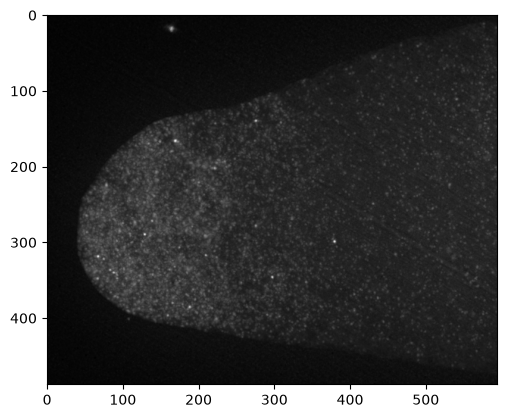

<class 'numpy.ndarray'>
['Batch 2/Img01_day8_mrna.tif', 'Batch 2/Img02_day8_mrna.tif', 'Batch 2/Img04_day8_mrna.tif']


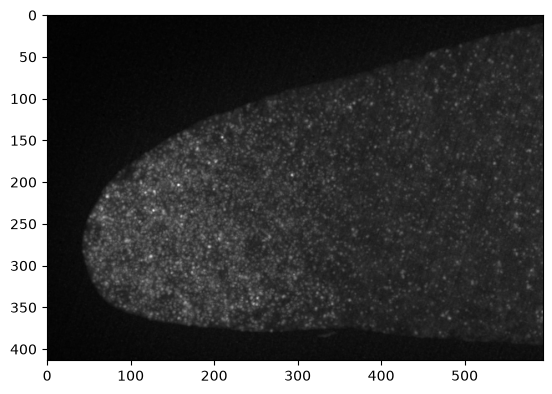

<class 'numpy.ndarray'>
['Batch 2/Img01_day8_mrna.tif', 'Batch 2/Img02_day8_mrna.tif', 'Batch 2/Img04_day8_mrna.tif']


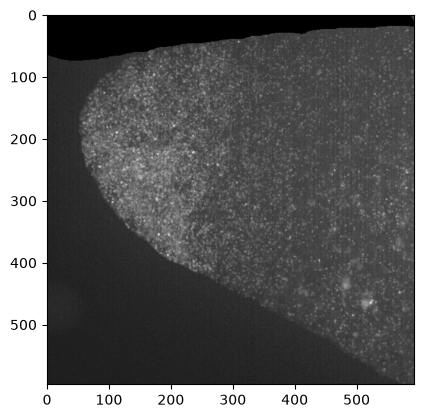

<class 'numpy.ndarray'>
['Batch 2/Img01_day8_mrna.tif', 'Batch 2/Img02_day8_mrna.tif', 'Batch 2/Img04_day8_mrna.tif']
                         Image  Single_mRNA
0  Batch 2/Img01_day8_mrna.tif         5604
1  Batch 2/Img02_day8_mrna.tif         4931
2  Batch 2/Img04_day8_mrna.tif         8599


In [101]:
counts = []
for file in filepaths:
    img_2 = tifffile.imread(file)
    plt.imshow(img_2, cmap="gray")
    plt.show()
    print(type(img_2))
    print(filepaths)

    img_2_norm = (img_2 - img_2.min()) / (img_2.max() - img_2.min())

    spots = feature.blob_log(img_2_norm, min_sigma=1, max_sigma=4, num_sigma=10, threshold=0.01, overlap=0.1)
    if len(spots) > 0:
        single_count = int((spots[:, 2] <= 2.0).sum())
    else:
        single_count = 0

    counts.append({"Image": str(file), "Single_mRNA": single_count})

counts_table = pd.DataFrame(counts)
print(counts_table)

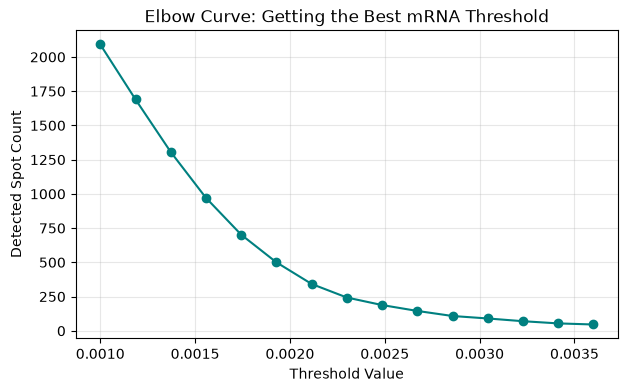

In [102]:
img_2 = tifffile.imread(filepaths[0])
img_2_float = img_as_float(img_2)

thresholds = np.linspace(0.001, 0.0036, 15)
spot_counts = []
for t in thresholds:
    spots = blob_log(img_2_float, min_sigma=1, max_sigma=3, threshold=t, overlap=0.0)
    spot_counts.append(len(spots))

plt.figure(figsize=(7, 4))
plt.plot(thresholds, spot_counts, marker="o", color="teal")
plt.xlabel("Threshold Value")
plt.ylabel("Detected Spot Count")
plt.title("Elbow Curve: Getting the Best mRNA Threshold")
plt.grid(True, alpha=0.3)
plt.show()

In [103]:
drops = -np.diff(spot_counts)
elbow_index = np.argmax(np.diff(drops)) + 1
best_thresh = thresholds[elbow_index]
print(f"Suggested Elbow Threshold: {best_thresh:.4f}")
print(f"Spots detected at this threshold: {spot_counts[elbow_index]}")

Suggested Elbow Threshold: 0.0030
Spots detected at this threshold: 90


In [104]:
counts = []
for file in filepaths:
    img_2 = tifffile.imread(file)
    img_2_float = img_as_float(img_2)
    spots = blob_log(img_2_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    counts.append({"Image": os.path.basename(file), "Total_Unique_Particles": len(spots)})

    counts_table = pd.DataFrame(counts)
    print(counts_table)

                 Image  Total_Unique_Particles
0  Img01_day8_mrna.tif                     429
                 Image  Total_Unique_Particles
0  Img01_day8_mrna.tif                     429
1  Img02_day8_mrna.tif                     560
                 Image  Total_Unique_Particles
0  Img01_day8_mrna.tif                     429
1  Img02_day8_mrna.tif                     560
2  Img04_day8_mrna.tif                    1314


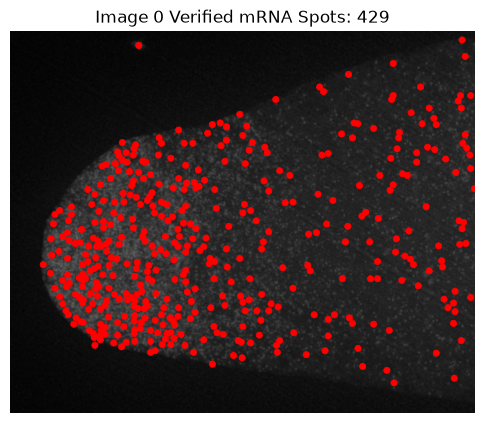

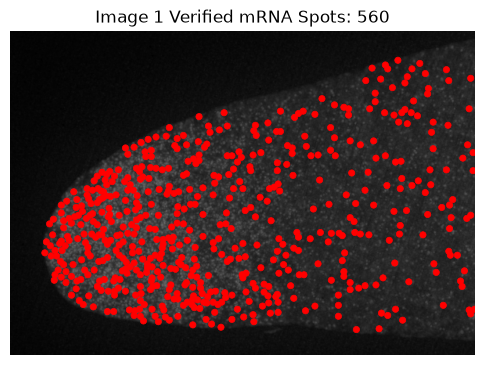

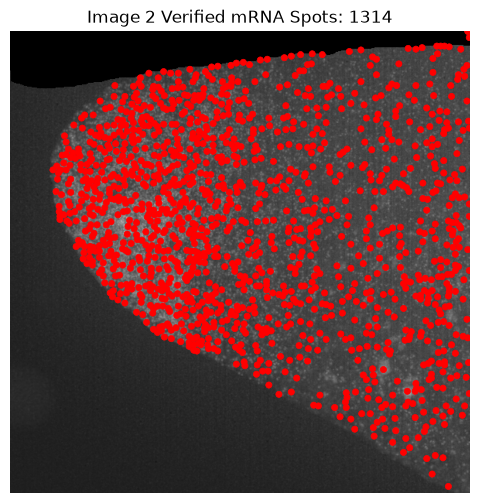

In [105]:
for i, file in enumerate (filepaths):
    img_2 = tifffile.imread(file)
    img_2_float = img_as_float(img_2)
    spots = blob_log(img_2_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    fh, ax = plt.subplots(figsize=(6, 6))
    plt.imshow(img_2, cmap="gray")
    for spot in spots:
        y, x, r = spot
        circle = plt.Circle((x, y), radius=4, color="red", linewidth=0.5, fill=True)
        ax.add_patch(circle)

    ax.set_title(f"Image {i} Verified mRNA Spots: {len(spots)}")
    ax.axis("off")
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch 2/verified_mrna_{i}.png")
    plt.close(fig)

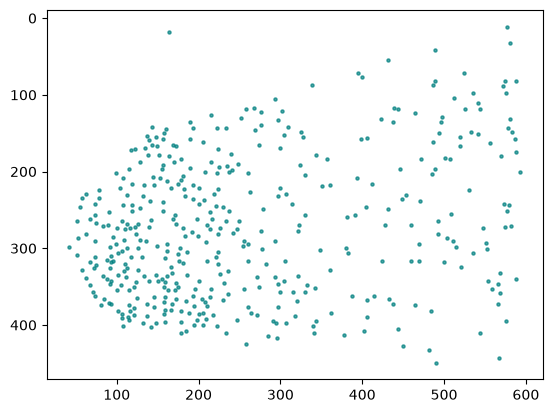

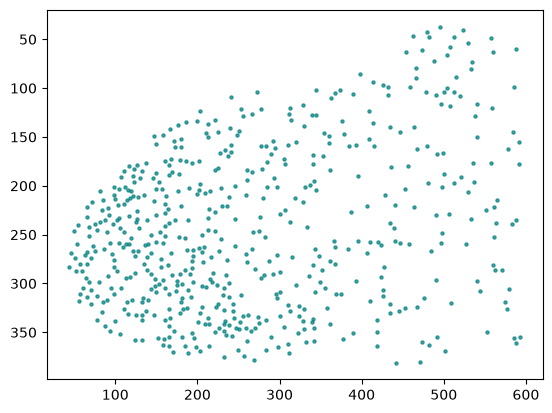

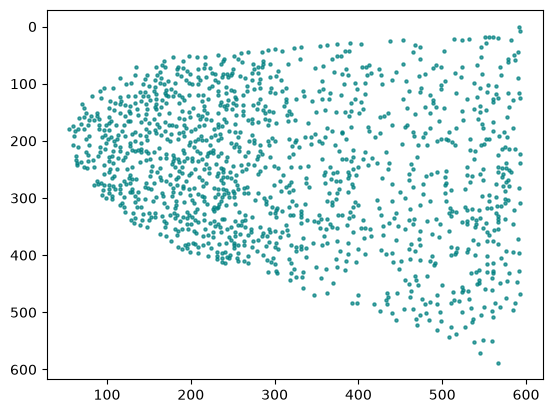

In [106]:
for i, file in enumerate (filepaths):
    img_2 = tifffile.imread(file)
    img_2_float = img_as_float(img_2)
    spots = blob_log(img_2_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    y = spots[:, 1]
    x = spots[:, 0]
    plt.scatter(y, x, s=20, alpha=0.7, c="teal", marker=".")
    plt.gca().invert_yaxis()
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch 2/figure_{i}.png")
    plt.show()
    plt.close()

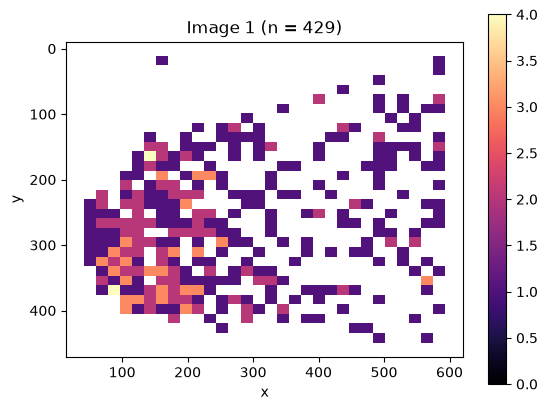

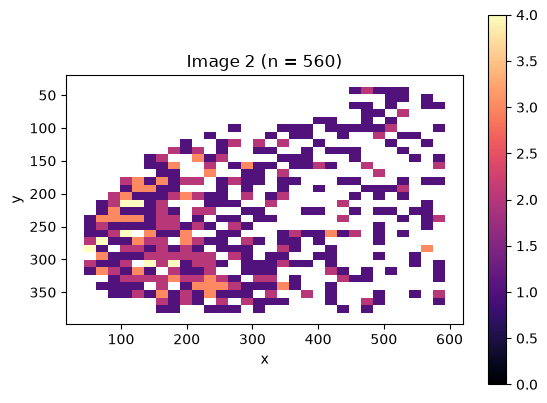

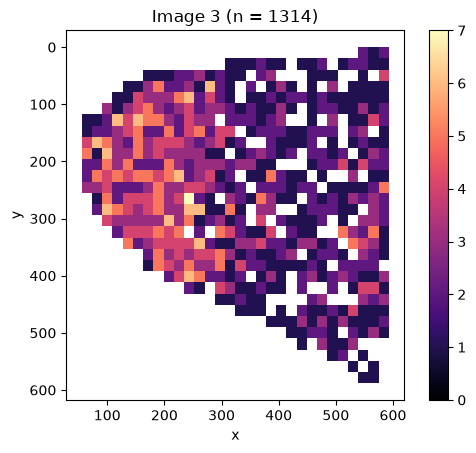

In [110]:
all_spots_2 = []
for i, file in enumerate(filepaths[:3]):
    img_2 = tifffile.imread(file)
    img_2_float = img_as_float(img_2)
    spots = blob_log(img_2_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    df = pd.DataFrame(spots, columns=["y", "x", "sigma"])
    df["Image"] = f"Image {i + 1}"
    all_spots_2.append(df)

    sns.histplot(data=df, x="x", y="y", bins=30, cmap="magma", cbar=True)
    plt.gca().invert_yaxis()
    plt.gca().set_aspect("equal")
    plt.title(f"Image {i +1} (n = {len(df)})")
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch 2/histplot_{i}.png")
    plt.show()
    plt.close()

In [111]:
spots_df_2 = pd.concat(all_spots, ignore_index=True)
print(spots_df_2.head())
print(spots_df_2["Image"].value_counts())
print(spots_df_2.tail())

       y      x     sigma    Image
0  289.0  129.0  1.222222  Image 1
1  299.0  380.0  1.222222  Image 1
2  166.0  169.0  1.444444  Image 1
3  346.0  297.0  1.222222  Image 1
4  318.0   67.0  1.222222  Image 1
Image
Image 3    1314
Image 2     560
Image 1     429
Name: count, dtype: int64
          y      x  sigma    Image
2298  447.0  589.0    1.0  Image 3
2299  140.0  493.0    1.0  Image 3
2300  225.0  567.0    1.0  Image 3
2301  219.0   92.0    1.0  Image 3
2302  149.0  373.0    1.0  Image 3


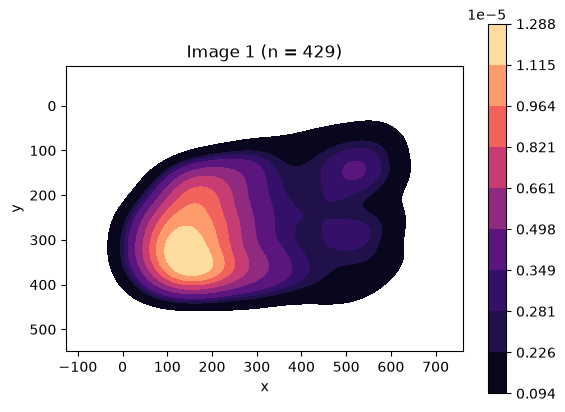

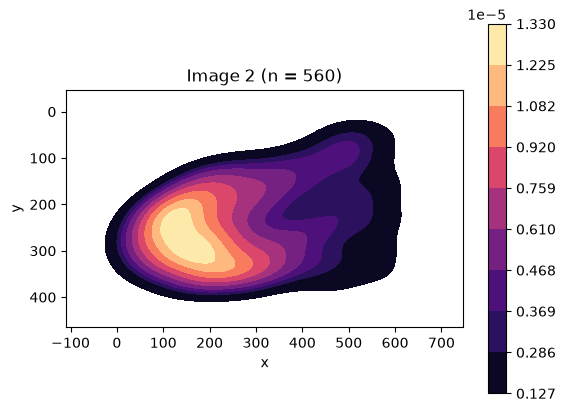

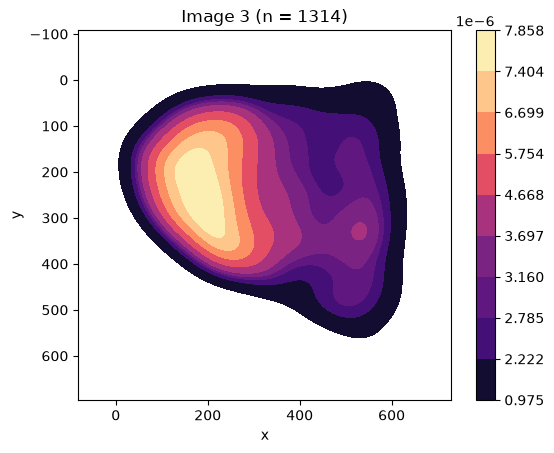

In [112]:
all_spots_2 = []
for i, file in enumerate(filepaths[:3]):
    img_2 = tifffile.imread(file)
    img_2_float = img_as_float(img_2)
    spots = blob_log(img_2_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    df = pd.DataFrame(spots, columns=["y", "x", "sigma"])
    df["Image"] = f"Image {i + 1}"
    all_spots_2.append(df)

    sns.kdeplot(data=df, x="x", y="y", fill=True, cmap="magma", cbar=True)
    plt.gca().invert_yaxis()
    plt.gca().set_aspect("equal")
    plt.title(f"Image {i +1} (n = {len(df)})")
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch 2/kde_heatmap_{i}.png")
    plt.show()
    plt.close()

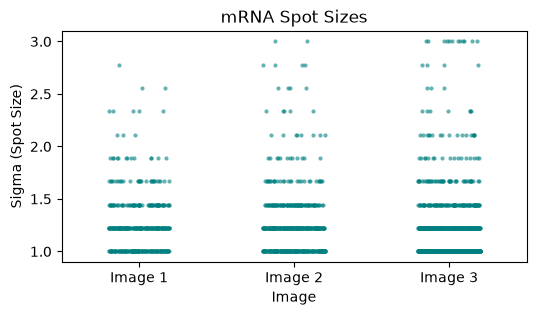

In [113]:
fh, ax = plt.subplots(1, 1, figsize=(6, 3))
sns.stripplot(data=spots_df_2, x="Image", y="sigma", color="teal", size=3, jitter=0.2, alpha=0.6, ax=ax)
plt.ylabel("Sigma (Spot Size)")
plt.title("mRNA Spot Sizes")
plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch 2/stripplot.png")
plt.show()

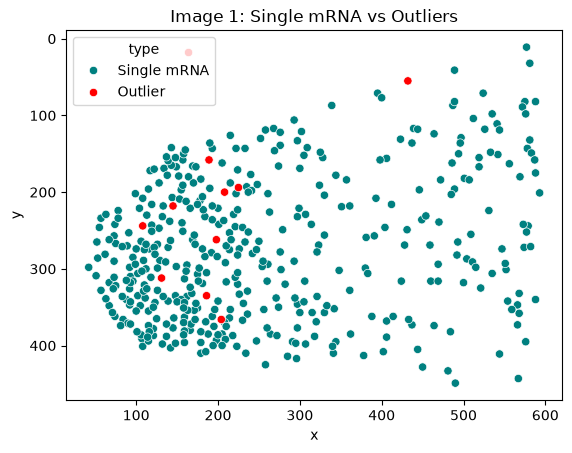

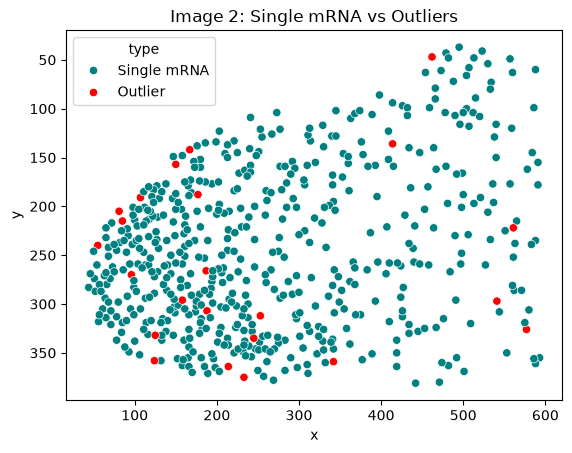

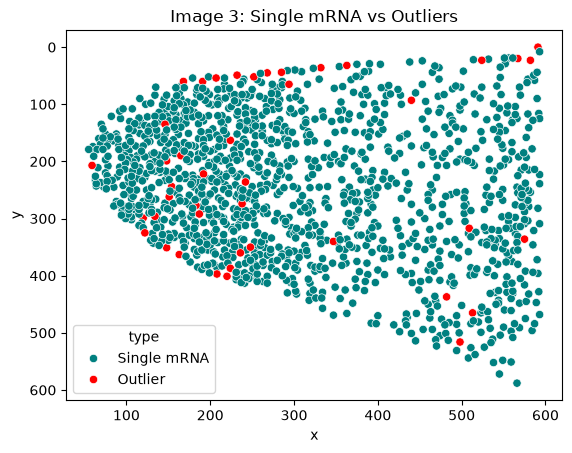

In [114]:
spots_df_2["type"] = np.where(spots_df_2["sigma"] > 2.0, "Outlier", "Single mRNA")
for i, img_name in enumerate(spots_df_2["Image"].unique()):
    sub_df_2 = spots_df_2[spots_df_2["Image"] == img_name]
    sns.scatterplot(data=sub_df_2, x="x", y="y", hue="type", palette={"Single mRNA": "teal", "Outlier": "red"})
    plt.gca().invert_yaxis()
    plt.title(f"{img_name}: Single mRNA vs Outliers")
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch 2/mrna_vs_outlier_scatter_{i}.png")
    plt.show()
    plt.close()

In [115]:
spots_df_2["type"] = np.where(spots_df_2["sigma"] > 2.0, "Outlier", "Single mRNA")
for i, img_name in enumerate(spots_df_2["Image"].unique()):
    sub_df_2 = spots_df_2[spots_df_2["Image"] == img_name]
    counts_table = sub_df_2["type"].value_counts().reset_index()
    counts_table.columns = ["Type", "Count"]
    counts_table.to_csv(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch 2/mrna_vs_outlier_scatter_{i}.csv", index=False)
    print(counts_table)

          Type  Count
0  Single mRNA    418
1      Outlier     11
          Type  Count
0  Single mRNA    537
1      Outlier     23
          Type  Count
0  Single mRNA   1271
1      Outlier     43


In [124]:
spots_df_2["type"] = np.where(spots_df_2["sigma"] > 2.0, "Outlier", "Single mRNA")
for i, img_name in enumerate(spots_df_2["Image"].unique()):
    sub_df_2 = spots_df_2[spots_df_2["Image"] == img_name]
    sub_summary_2 = sub_df_2.groupby("type", as_index=False).agg(Count=("sigma", "count"), Mean_Sigma=("sigma", "mean"), Min_Sigma=("sigma", "min"), Max_Sigma=("sigma", "max"))
    sub_summary_2 = sub_summary_2.round(2)
    print(f"{img_name} Summary")
    print(sub_summary_2)
    sub_summary_2.to_csv(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch 2/sub_summary_{i}.csv", index=False)

Image 1 Summary
          type  Count  Mean_Sigma  Min_Sigma  Max_Sigma
0      Outlier     11        2.35       2.11       2.78
1  Single mRNA    418        1.23       1.00       1.89
Image 2 Summary
          type  Count  Mean_Sigma  Min_Sigma  Max_Sigma
0      Outlier     23        2.43       2.11       3.00
1  Single mRNA    537        1.22       1.00       1.89
Image 3 Summary
          type  Count  Mean_Sigma  Min_Sigma  Max_Sigma
0      Outlier     43        2.49       2.11       3.00
1  Single mRNA   1271        1.13       1.00       1.89


In [130]:
results_2 = []
for i, file in enumerate(filepaths[:3]):
    img_2 = tifffile.imread(file)
    spots = feature.blob_log(util.img_as_float(img_2), min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    area = (img_2 > filters.threshold_triangle(img_2)).sum()

    results_2.append({"Stage": "Day 8", "Spots": len(spots), "Density_per_ik_px": round((len(spots) / area) * 1000, 2)})

df = pd.DataFrame(results_2)
print(df)

   Stage  Spots  Density_per_ik_px
0  Day 8    429               2.32
1  Day 8    560               3.59
2  Day 8   1314               3.99


In [146]:
# Statistical Analysis between Day 1 and Day 8
from scipy.stats import mannwhitneyu, chi2_contingency, ttest_ind
from scipy.spatial import KDTree

In [148]:
# 1.) Raw/Initial Single mRNA Counts t-test
day1_single = [1629, 1930]
day8_single = [5604, 4931, 8599]

_, p_val = ttest_ind(day1_single, day8_single, equal_var=False)

print(f"Day 1 Single mRNA: {np.mean(day1_single):.1f} += {np.std(day1_single, ddof=1):.1f}")
print(f"Day 8 Single mRNA: {np.mean(day8_single):.1f} += {np.std(day8_single, ddof=1):.1f}")
print(f"p-value: {p_val:.4f}")

Day 1 Single mRNA: 1779.5 += 212.8
Day 8 Single mRNA: 6378.0 += 1952.7
p-value: 0.0529


In [150]:
# 2.) Unique Isolated Particles t-test
day1_unique = [396, 404]
day8_unique = [429, 560, 1314]

_, p_val = ttest_ind(day1_unique, day8_unique, equal_var=False)

print(f"Day 1 Unique Isolated mRNA: {np.mean(day1_unique):.1f} += {np.std(day1_unique, ddof=1):.1f}")
print(f"Day 8 Unique Isolated mRNA: {np.mean(day8_unique):.1f} += {np.std(day8_unique, ddof=1):.1f}")
print(f"p-value: {p_val:.4f}")

Day 1 Unique Isolated mRNA: 400.0 += 5.7
Day 8 Unique Isolated mRNA: 767.7 += 477.7
p-value: 0.3140


In [151]:
# 3.) Single mRNA & Outlier Welch's t-tests
day1_single = np.array([381, 392])
day1_outlier = np.array([15, 12])

day8_single = np.array([418, 537, 1271])
day8_outlier = np.array([11, 23, 43])

_, p_single = ttest_ind(day1_single, day8_single, equal_var=False)
print(f"Day 1 Single mRNA: {day1_single.mean():.1f} += {day1_single.std(ddof=1):.1f}")
print(f"Day 8 Single mRNA: {day8_single.mean():.1f} += {day8_single.std(ddof=1):.1f}")
print(f"Single mRNA p-value: {p_single:.4f}")

_, p_outlier = ttest_ind(day1_outlier, day8_outlier, equal_var=False)
print(f"Day 1 Outliers: {day1_outlier.mean():.1f} += {day1_outlier.std(ddof=1):.1f}")
print(f"Day 8 Outliers: {day8_outlier.mean():.1f} += {day8_outlier.std(ddof=1):.1f}")
print(f"mRNA Outliers p-value: {p_outlier:.4f}")

Day 1 Single mRNA: 386.5 += 7.8
Day 8 Single mRNA: 742.0 += 462.0
Single mRNA p-value: 0.3141
Day 1 Outliers: 13.5 += 2.1
Day 8 Outliers: 25.7 += 16.2
mRNA Outliers p-value: 0.3216


In [152]:
# 4.) Pooled Chi-Square ratio test
table = [[day1_single.sum(), day1_outlier.sum()], [day8_single.sum(), day8_outlier.sum()]]
_, p_chi2, _, _ = chi2_contingency(table)
print(f"Pooled Chi-Square Ratio p-value: {p_chi2:.4f}")

Pooled Chi-Square Ratio p-value: 1.0000


In [141]:
# Between the densities -- based on tissue area to account for differences in gonad size as aging progresses
day1 = [2.32, 3.59]
day8 = [2.32, 3.59, 3.99]

# 1.) Non-parametric p-value -- Mann-Whitney U test
_, p_mwu = mannwhitneyu(day1, day8)
print(f"Mann-Whitney p-value: {p_mwu:.4f}")

Mann-Whitney p-value: 0.7609


In [142]:
# 2.) Variation Coefficient (std dev / mean) -- biological noise
day1_cv = np.std(day1, ddof=1) / np.mean(day1)
print(f"Day 1 Noise (CV): {day1_cv:.2f}")

day8_cv = np.std(day8, ddof=1) / np.mean(day8)
print(f"Day 8 Noise (CV): {day8_cv:.2f}")

Day 1 Noise (CV): 0.30
Day 8 Noise (CV): 0.26


In [144]:
# 3.) Finding nearest-neighbor distance
tree = KDTree(spots[:, :2])
dists, _ = tree.query(spots[:, :2], k=2)
print(f"Mean Nearest-Neighbor Distance: {dists[:, 1].mean():.2f} pixels")

Mean Nearest-Neighbor Distance: 7.57 pixels


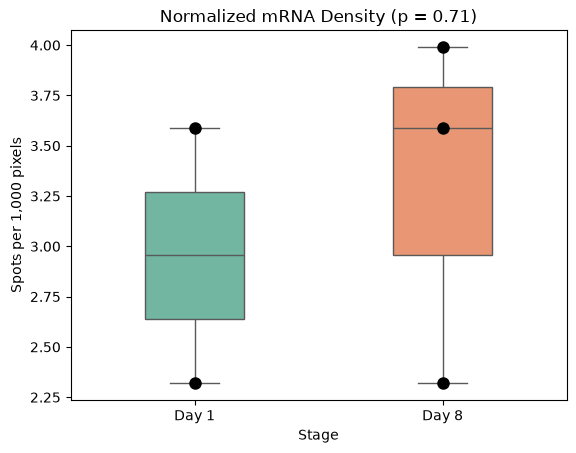

In [153]:
# Plotting Comparisons between Day 1 and Day 8
# 1.) Normalized mRNA Density 
df = pd.DataFrame({"Stage": ["Day 1", "Day 1", "Day 8", "Day 8", "Day 8"], "Density": [2.32, 3.59, 2.32, 3.59, 3.99]})

sns.boxplot(data=df, x="Stage", y="Density", hue="Stage", palette="Set2", width=0.4, legend=False)
sns.swarmplot(data=df, x="Stage", y="Density", color="black", size=9)

plt.title("Normalized mRNA Density (p = 0.71)")
plt.ylabel("Spots per 1,000 pixels")
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/plot1_density.png", dpi=300, bbox_inches="tight")
plt.show()

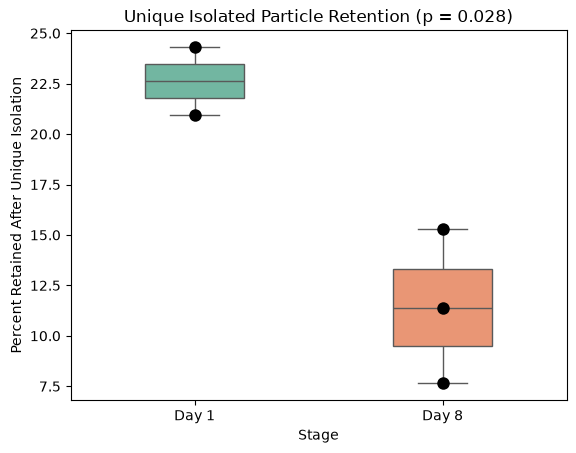

In [155]:
# 2.) Unique Isolated mRNA Retention
df = pd.DataFrame({"Stage": ["Day 1", "Day 1", "Day 8", "Day 8", "Day 8"], "Retained_Pct": [396 / 1629 * 100, 404 / 1930 * 100, 429 / 5604 * 100, 560 / 4931 * 100, 1314 / 8599 * 100]})

sns.boxplot(data=df, x="Stage", y="Retained_Pct", hue="Stage", palette="Set2", width=0.4, legend=False)
sns.swarmplot(data=df, x="Stage", y="Retained_Pct", color="black", size=9)

plt.title("Unique Isolated Particle Retention (p = 0.028)")
plt.ylabel("Percent Retained After Unique Isolation")
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/plot2_retention.png", dpi=300, bbox_inches="tight")
plt.show()

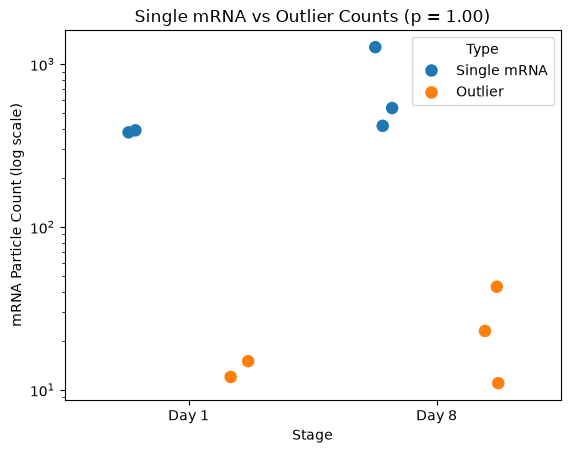

In [166]:
# 3.) mRNA Particle Size Composition
df = pd.DataFrame({"Stage": ["Day 1", "Day 1", "Day 1", "Day 1", "Day 8", "Day 8", "Day 8", "Day 8", "Day 8", "Day 8"], "Type": ["Single mRNA", "Outlier", "Single mRNA", "Outlier", "Single mRNA", "Outlier", "Single mRNA", "Outlier", "Single mRNA", "Outlier"], "Count": [381, 15, 392, 12, 418, 11, 537, 23, 1271, 43]})

sns.stripplot(data=df, x="Stage", y="Count", hue="Type", size=9, dodge=True, jitter=0.1)
plt.yscale("log")
plt.title("Single mRNA vs Outlier Counts (p = 1.00)")
plt.ylabel("mRNA Particle Count (log scale)")
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/plot3_log_strip.png", dpi=300, bbox_inches="tight")
plt.show()